# 06 — Model Optimization, Round 2: Bayesian Search with Optuna

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric section:** Model Optimization

Round 1 (notebook 05) tuned the GRU one setting at a time and brought it to **144.0 km** on the validation
seasons. It also left three honest gaps:

- **Untouched settings.** Learning rate, dropout, weight decay and batch size were never tuned.
- **One setting at a time.** Changing settings separately can miss combinations that only help together.
- **Flattering validation score.** The validation seasons were used to choose the settings, which makes
  their score slightly optimistic.

So for round 2 we switch to a different method, **Bayesian optimization**, using the Optuna library (Akiba
et al., 2019). Instead of a fixed list of configurations, Optuna treats tuning as a search problem. After
each trial, it updates a probabilistic picture of which regions of the settings space look promising,
specifically the Tree-structured Parzen Estimator, or TPE (Bergstra et al., 2011). It then picks the next
trial from those regions. Along the way, a **pruner** watches each trial's learning curve and stops runs
that are clearly falling behind, so compute goes where it's useful.

Round 2 also fixes the third gap with a cleaner protocol:

| Seasons | Role in round 2 |
|---|---|
| 1980–2013 | train every trial |
| **2014–2016** | **score every trial: the search only ever sees these** |
| 2017–2019 (validation) | untouched by the search; used only for the final round 1 vs round 2 comparison |
| 2020–2024 (test) | still locked |

Because the validation seasons play no part in choosing round 2's settings, its validation score is an
honest one. That makes the comparison with round 1, whose score is slightly flattering, a fair and even
slightly demanding test.

| | |
|---|---|
| **Input** | `data/processed/tracks_clean.csv.gz`; earlier validation errors from notebooks 03–05 |
| **Output** | `data/processed/optuna_trials.csv`, `preds_val_round2.csv`, `models/round2_*`, figures `fig20`–`fig22` |

### Setting things up

Along with the usual project code, here we import Optuna. The training loop in `rnn.py` gained one small
hook, `on_epoch`, which reports each epoch's error back to Optuna and lets the pruner stop a trial early.
As before, XGBoost isn't imported (it can't share a session with PyTorch on macOS), and CPU work is capped
at 4 threads.

In [1]:
# Imports and paths
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import optuna

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_clean, PROCESSED
from stormtrack.windows import (build_samples, build_sequences, persistence_displacement, track_error_km,
                                TARGET_COLS, STEP_FEATURES, STATIC_COLS)
from stormtrack.rnn import RNNForecaster, train_model, predict

FIG_DIR, MODEL_DIR = ROOT / "reports" / "figures", ROOT / "models"
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
SEED, FINAL_SEEDS = 42, [42, 7, 2024]
optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f"PyTorch {torch.__version__} | Optuna {optuna.__version__} | training on: {DEVICE}")

pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}")

PyTorch 2.15.0 | Optuna 5.1.0 | training on: mps


## 1. Splitting off a tuning set inside the training years

First, we rebuild the familiar forecast samples and their static features. Then, within the training
seasons (1980–2016), the cell below marks the last three seasons, 2014–2016, as the **tuning set**. Every
Optuna trial trains on 1980–2013 and is scored on 2014–2016.

Three seasons mirrors the size of the validation period, and taking the *most recent* training seasons keeps
the setup realistic, since a model is always tuned on the past and used on the future.

In [2]:
tracks = load_clean()
S = build_samples(tracks)
BASINS = sorted(S["BASIN"].unique())
for b in BASINS:
    S[f"basin_{b}"] = (S["BASIN"] == b).astype(float)
STATIC = STATIC_COLS + [f"basin_{b}" for b in BASINS]

is_fit = (S["split"].eq("train") & S["SEASON"].le(2013)).to_numpy()      # trains every trial
is_tune = (S["split"].eq("train") & S["SEASON"].ge(2014)).to_numpy()     # scores every trial
is_tr, is_va = S["split"].eq("train").to_numpy(), S["split"].eq("val").to_numpy()
pd.DataFrame({"seasons": ["1980-2013", "2014-2016", "1980-2016", "2017-2019"],
              "samples": [is_fit.sum(), is_tune.sum(), is_tr.sum(), is_va.sum()],
              "storms": [S.loc[m, "SID"].nunique() for m in (is_fit, is_tune, is_tr, is_va)]},
             index=["search: fit", "search: tune", "final: train", "final: validation"])

,seasons,samples,storms
search: fit,1980-2013,60512,3039
search: tune,2014-2016,4657,263
final: train,1980-2016,65169,3302
final: validation,2017-2019,4699,275


Next, the sequences. Since history length is one of the settings Optuna will search, we prepare every
option from 3 to 11 steps (24 to 72 hours). The helper below scales them in the same way as notebook 05:
statistics come from real (not padded) steps of whichever training set is in use, and padding stays at
exactly zero.

Here, the "whichever training set" detail matters. During the search, the scaling statistics come from
1980–2013 only, so the tuning seasons can't leak into training through the scaling. For the final models,
they come from all of 1980–2016, as in rounds before.

In [3]:
P = persistence_displacement(S)
Y = S[TARGET_COLS].to_numpy() - P                         # correction to persistence, km
ST = S[STATIC].to_numpy()
STEP_OPTIONS = [3, 5, 7, 9, 11]
SEQS = {n: build_sequences(tracks, S, n_steps=n) for n in STEP_OPTIONS}

def make_tensors(n_steps, fit_mask, eval_mask):
    seq = SEQS[n_steps]
    real = seq[fit_mask][..., -1] == 1
    mu, sd = seq[fit_mask][real].mean(0), seq[fit_mask][real].std(0)
    mu[-1], sd[-1] = 0.0, 1.0
    scaled = np.where(seq[..., -1:] == 1, (seq - mu) / sd, 0.0).astype(np.float32)
    s_mu, s_sd = ST[fit_mask].mean(0), ST[fit_mask].std(0)
    s_sd[s_sd == 0] = 1.0
    y_sc = Y[fit_mask].std(0)
    t = lambda m: (torch.tensor(scaled[m]), torch.tensor((ST[m] - s_mu) / s_sd, dtype=torch.float32),
                   torch.tensor(Y[m] / y_sc, dtype=torch.float32))
    stats = {"seq_mu": mu.tolist(), "seq_sd": sd.tolist(), "st_mu": s_mu.tolist(), "st_sd": s_sd.tolist(),
             "y_scale": y_sc.tolist()}
    return t(fit_mask), t(eval_mask), y_sc, stats

SEARCH_T = {n: make_tensors(n, is_fit, is_tune) for n in STEP_OPTIONS}
print("Search tensors ready for", STEP_OPTIONS, "steps")

Search tensors ready for [3, 5, 7, 9, 11] steps


## 2. The search space

Here is what Optuna is allowed to vary. Compared with round 1, it can now change everything at once, and it
also covers the four training settings that round 1 left at their defaults:

| Setting | Range | Round 1 value |
|---|---|---|
| Recurrent cell | GRU or LSTM | GRU |
| History length | 3, 5, 7, 9 or 11 steps (24–72 h) | 7 steps |
| Hidden units | 64, 96, 128, 192 or 256 | 128 |
| Recurrent layers | 1 or 2 | 1 |
| Dropout | 0 to 0.4 | 0.1 |
| Learning rate | 0.0003 to 0.003 (log scale) | 0.001 |
| Weight decay | 0.000001 to 0.01 (log scale) | 0.0001 |
| Batch size | 256, 512 or 1024 | 512 |

In the objective function below, one set of choices becomes a single number. It builds the network, trains it on
1980–2013 with early stopping (at most 60 epochs), and returns its best mean distance error on 2014–2016.
After every epoch, it reports the current error to Optuna. If the pruner decides the trial is clearly
worse than earlier trials were at the same epoch, it stops the trial on the spot.

In [4]:
def objective(trial):
    cfg = {"cell": trial.suggest_categorical("cell", ["gru", "lstm"]),
           "n_steps": trial.suggest_categorical("n_steps", STEP_OPTIONS),
           "hidden": trial.suggest_categorical("hidden", [64, 96, 128, 192, 256]),
           "layers": trial.suggest_int("layers", 1, 2),
           "dropout": trial.suggest_float("dropout", 0.0, 0.4),
           "lr": trial.suggest_float("lr", 3e-4, 3e-3, log=True),
           "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
           "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024])}
    fit_t, tune_t, y_sc, _ = SEARCH_T[cfg["n_steps"]]

    def report(epoch, val_km):
        trial.report(val_km, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    torch.manual_seed(SEED)
    model = RNNForecaster(len(STEP_FEATURES), len(STATIC), cell=cfg["cell"], hidden=cfg["hidden"],
                          layers=cfg["layers"], dropout=cfg["dropout"])
    t0 = time.time()
    _, hist = train_model(model, fit_t, tune_t, y_sc, DEVICE, epochs=60, patience=8, seed=SEED,
                          lr=cfg["lr"], weight_decay=cfg["weight_decay"], batch_size=cfg["batch_size"],
                          verbose=False, on_epoch=report)
    trial.set_user_attr("epochs", len(hist))
    trial.set_user_attr("secs", round(time.time() - t0))
    return min(h["val_km"] for h in hist)

## 3. Running the search

Now we set the study up. Three choices are worth spelling out:

- **Sampler:** TPE with a fixed seed, so the whole search can be reproduced.
- **Pruner:** Optuna's median pruner. Once 8 trials have finished, any new trial whose error after
  epoch 10 or later is worse than the median of earlier trials at that same epoch gets stopped.
- **First trial:** round 1's winning configuration, queued by hand. That way the search starts from
  the best known point, and we get round 1's score on the tuning seasons for a fair, like-for-like
  reference.

With **40 trials** in total, the search takes roughly 15–25 minutes on the laptop, depending on how many
trials get pruned. The cell prints a short line for each finished trial.

In [5]:
ROUND1 = {"cell": "gru", "n_steps": 7, "hidden": 128, "layers": 1, "dropout": 0.1, "lr": 1e-3,
          "weight_decay": 1e-4, "batch_size": 512}
study = optuna.create_study(direction="minimize", study_name="gru_lstm_round2",
                            sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=10))
study.enqueue_trial(ROUND1)

def progress(study, trial):
    state = "pruned" if trial.state == optuna.trial.TrialState.PRUNED else f"{trial.value:6.1f} km"
    p = trial.params
    print(f"trial {trial.number:2d}: {state:>9s} | {p['cell']} {p['n_steps']} steps {p['hidden']}x{p['layers']} "
          f"drop {p['dropout']:.2f} lr {p['lr']:.4f} wd {p['weight_decay']:.0e} batch {p['batch_size']} "
          f"| best so far {study.best_value:.1f} km")

t0 = time.time()
study.optimize(objective, n_trials=40, callbacks=[progress])
print(f"\nSearch finished in {(time.time() - t0) / 60:.1f} minutes")

trial  0:  138.4 km | gru 7 steps 128x1 drop 0.10 lr 0.0010 wd 1e-04 batch 512 | best so far 138.4 km


trial  1:  138.8 km | lstm 3 steps 256x2 drop 0.08 lr 0.0005 wd 5e-06 batch 512 | best so far 138.4 km


trial  2:  139.4 km | lstm 11 steps 256x1 drop 0.03 lr 0.0027 wd 7e-03 batch 256 | best so far 138.4 km


trial  3:  139.3 km | gru 9 steps 64x2 drop 0.31 lr 0.0026 wd 4e-03 batch 512 | best so far 138.4 km


trial  4:  138.5 km | gru 9 steps 192x2 drop 0.31 lr 0.0005 wd 1e-06 batch 256 | best so far 138.4 km


trial  5:  138.3 km | gru 7 steps 192x2 drop 0.19 lr 0.0004 wd 7e-04 batch 1024 | best so far 138.3 km


... (30 outputs left out)

trial 36:    pruned | gru 5 steps 192x2 drop 0.32 lr 0.0030 wd 2e-03 batch 1024 | best so far 138.1 km


trial 37:  138.8 km | gru 5 steps 192x2 drop 0.14 lr 0.0023 wd 9e-04 batch 1024 | best so far 138.1 km


trial 38:    pruned | gru 7 steps 256x2 drop 0.35 lr 0.0011 wd 9e-06 batch 512 | best so far 138.1 km


trial 39:    pruned | gru 7 steps 192x2 drop 0.34 lr 0.0005 wd 2e-03 batch 1024 | best so far 138.1 km

Search finished in 12.5 minutes


So the search ran 40 trials in about 12.5 minutes. The pruner stopped 15 of them early, which is where most of the time savings came from.

Reading down the log, a pattern shows up quickly. After a few LSTM trials in the early, mostly random phase scored worse, Optuna concentrated almost entirely on GRUs, with larger hidden sizes, two layers, and batches of 1024. It's also striking how close the good trials are to each other. Round 1's configuration (trial 0) scored 138.4 km on 2014–2016, and the best trial reached only 138.1 km.

## 4. What did the search find?

Let's look at the results. The table below lists every completed trial, best first, with its settings, its
tuning-set error, and how long it trained. Round 1's configuration is trial 0, so its row gives the
reference point on these same seasons.

In [6]:
trials = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in trials.columns]
trials.to_csv(PROCESSED / "optuna_trials.csv", index=False)
done = trials[trials["state"] == "COMPLETE"].sort_values("value")
counts = trials["state"].value_counts().to_dict()
print(f"Trials: {counts}   |   round 1 config (trial 0) on 2014-2016: {trials.loc[0, 'value']:.1f} km")
done.head(10).round({"value": 1, "dropout": 2, "lr": 5, "weight_decay": 6}).set_index("number")

Trials: {'COMPLETE': 25, 'PRUNED': 15}   |   round 1 config (trial 0) on 2014-2016: 138.4 km


,value,state,batch_size,cell,dropout,hidden,layers,lr,n_steps,weight_decay,epochs,secs
number,,,,,,,,,,,,
21,138.1,COMPLETE,1024,gru,0.30,256,2,0.00090,7,0.000179,26.0,35.0
31,138.2,COMPLETE,1024,gru,0.36,256,2,0.00083,7,0.000012,21.0,28.0
35,138.2,COMPLETE,1024,gru,0.35,192,2,0.00096,7,0.001523,31.0,28.0
10,138.2,COMPLETE,1024,gru,0.13,192,2,0.00207,5,0.000592,17.0,11.0
17,138.2,COMPLETE,1024,gru,0.22,192,2,0.00079,7,0.009519,26.0,23.0
22,138.2,COMPLETE,1024,gru,0.37,256,2,0.00092,7,0.000239,21.0,28.0
32,138.3,COMPLETE,1024,gru,0.38,256,2,0.00078,11,0.000016,21.0,42.0
5,138.3,COMPLETE,1024,gru,0.19,192,2,0.00040,7,0.000713,43.0,39.0
16,138.4,COMPLETE,512,gru,0.10,256,2,0.00076,5,0.000756,25.0,26.0


Here's the key result. The top eight completed trials all land between 138.1 and 138.3 km, very different configurations that perform almost identically. The winner, trial 21, is a GRU with 48 hours of history, 256 hidden units in two layers, 30% dropout, a learning rate of about 0.0009, and batches of 1024. It improves on round 1's configuration by only **0.3 km** on the tuning seasons.

In other words, the error surface is very flat around its best region. Many reasonable settings give about the same answer, and round 1 had already found a spot in that flat region.

Looking at the history plot, it shows the same thing. The best-so-far line drops only slightly after trial 5 and stays flat for the last 18 trials, a sign that the search has converged rather than run out of time.

To see how the search progressed, Figure 20 plots every trial in order. Completed trials appear as dots,
pruned trials as small crosses at the error they had reached when they were stopped, and the line traces
the best result so far. A search that's still finding improvements near the end would suggest more trials
could help; a flat line suggests the search has converged.

saved reports/figures/fig20_optuna_history.png


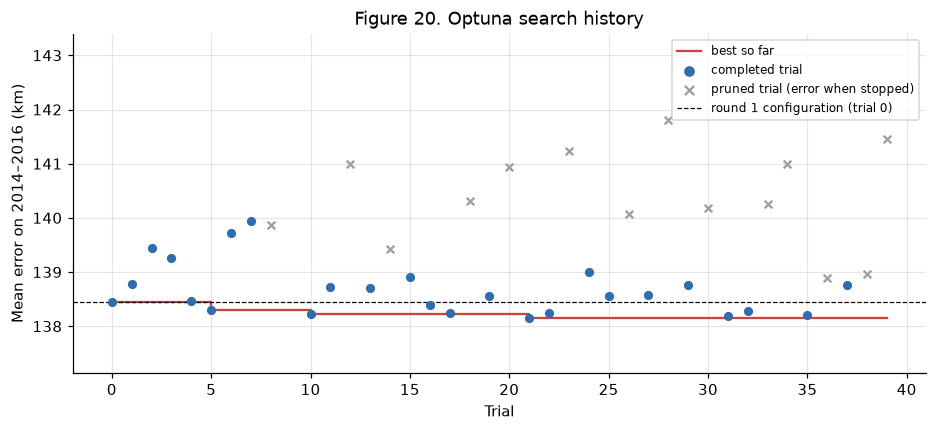

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for t in study.trials:
    if t.state == optuna.trial.TrialState.COMPLETE:
        ax.scatter(t.number, t.value, color="#2F6DB3", s=25, zorder=3)
    elif t.intermediate_values:
        ax.scatter(t.number, min(t.intermediate_values.values()), color="#9E9E9E", marker="x", s=25)
best_curve = np.minimum.accumulate([t.value if t.value is not None else np.inf for t in study.trials])
ax.step(range(len(best_curve)), best_curve, where="post", color="#C9453B", label="best so far")
ax.scatter([], [], color="#2F6DB3", label="completed trial")
ax.scatter([], [], color="#9E9E9E", marker="x", label="pruned trial (error when stopped)")
ax.axhline(trials.loc[0, "value"], color="k", ls="--", lw=0.8, label="round 1 configuration (trial 0)")
vals = [t.value for t in study.trials if t.value is not None]
ax.set(xlabel="Trial", ylabel="Mean error on 2014–2016 (km)", ylim=(min(vals) - 1, np.percentile(vals, 90) + 2),
       title="Figure 20. Optuna search history")
ax.legend(fontsize=8)
savefig(fig, "fig20_optuna_history.png")
plt.show()

Which settings actually mattered? Optuna can estimate each setting's **importance** with fANOVA (Hutter et
al., 2014). It fits a random forest that predicts a trial's error from its settings, then measures how much
of the variation in error each setting explains on its own. Figure 21 shows the result. Like any estimate
from 40 trials, it's a guide rather than a precise measurement.

saved reports/figures/fig21_optuna_importance.png


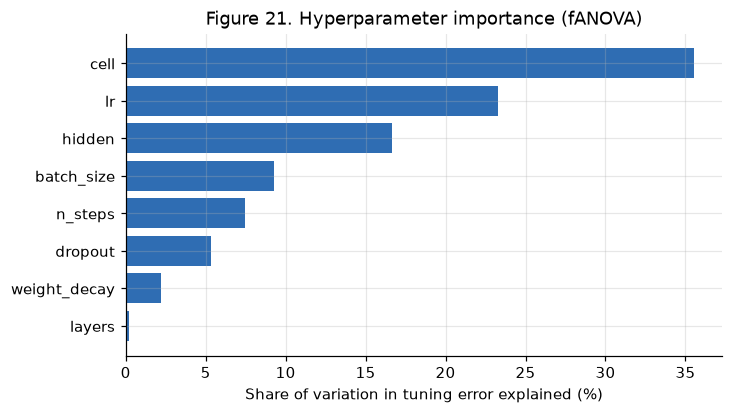

cell            35.5
lr              23.3
hidden          16.6
batch_size       9.3
n_steps          7.5
dropout          5.4
weight_decay     2.2
layers           0.2
dtype: float64

In [8]:
imp = optuna.importance.get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp.values * 100, color="#2F6DB3")
ax.set(xlabel="Share of variation in tuning error explained (%)", title="Figure 21. Hyperparameter importance (fANOVA)")
savefig(fig, "fig21_optuna_importance.png")
plt.show()
(imp.sort_values(ascending=False) * 100).round(1)

Looking at the importance chart:

- **Cell type** explains the most variation in error (about 36%). LSTM trials consistently scored worse than GRU trials, which matches notebooks 04 and 05.
- **Learning rate** comes next (23%), followed by **hidden size** (17%), batch size (9%) and history length (7.5%).
- **Dropout and weight decay** matter little.
- **Number of layers** barely registers (0.2%), even though the top trials all happen to use two layers. On its own, adding a second layer doesn't change the error much, which fits round 1's finding.

So the settings round 1 never touched, especially the learning rate, did matter. But round 1's default of 0.001 was already in the right range.

## 5. Training the round 2 model

With the search done, the best configuration gets trained exactly as round 1's was, so the two can be
compared on equal terms:

- trained on all training seasons (1980–2016), with scaling statistics from those seasons,
- early-stopped on the validation seasons,
- with three seeds (42, 7 and 2024), averaged into an ensemble.

One subtlety: the number of epochs is still chosen by early stopping on the validation seasons, exactly as
in round 1. All the *settings*, though, were chosen without ever looking at them.

In [9]:
BEST = dict(study.best_params)
print("Best configuration:", BEST)
fin_train, fin_val, fin_ysc, fin_stats = make_tensors(BEST["n_steps"], is_tr, is_va)
va = S[is_va].reset_index(drop=True)
P_va = P[is_va]

disp, runs = [], []
for seed in FINAL_SEEDS:
    torch.manual_seed(seed)
    model = RNNForecaster(len(STEP_FEATURES), len(STATIC), cell=BEST["cell"], hidden=BEST["hidden"],
                          layers=BEST["layers"], dropout=BEST["dropout"])
    model, hist = train_model(model, fin_train, fin_val, fin_ysc, DEVICE, seed=seed, lr=BEST["lr"],
                              weight_decay=BEST["weight_decay"], batch_size=BEST["batch_size"], verbose=False)
    torch.save(model.state_dict(), MODEL_DIR / f"round2_{BEST['cell']}_seed{seed}.pt")
    d = predict(model, fin_val[0], fin_val[1], DEVICE) * fin_ysc + P_va
    disp.append(d)
    runs.append({"seed": seed, "val_mean_km": track_error_km(va, d).mean(), "epochs": len(hist)})
seed_tab = pd.DataFrame(runs).set_index("seed").round(1)
print(f"Single runs: mean {seed_tab['val_mean_km'].mean():.2f} km, spread {seed_tab['val_mean_km'].min()}-{seed_tab['val_mean_km'].max()} km")
seed_tab

Best configuration: {'cell': 'gru', 'n_steps': 7, 'hidden': 256, 'layers': 2, 'dropout': 0.29899104316725633, 'lr': 0.000902040696761779, 'weight_decay': 0.00017882217310984675, 'batch_size': 1024}


Single runs: mean 144.53 km, spread 144.5-144.6 km


,val_mean_km,epochs
seed,,
42,144.5,30
7,144.5,25
2024,144.6,31


Trained on all of 1980–2016 with three seeds, the round 2 configuration scores 144.5 to 144.6 km per run, a remarkably tight spread. That's tighter than round 1's 144.3 to 144.8 km, probably thanks to the heavier 30% dropout. A single round 2 run averages 144.53 km, essentially the same as a single round 1 run (144.57 km).

## 6. Round 1 or round 2?

Now for the comparison that decides the final model. The cell below loads the saved validation errors of
every earlier model, adds the round 2 ensemble, and builds the summary table. Keep in mind that round 1's
number is slightly flattering, because round 1 was tuned on these very seasons, while round 2's is not.

In [10]:
kw = dict(keep_default_na=False, na_values=[""], parse_dates=["ISO_TIME"])   # keep basin code "NA" as text
base = pd.read_csv(PROCESSED / "preds_val_baselines.csv", **kw)
tuned = pd.read_csv(PROCESSED / "preds_val_tuned.csv", **kw)
for f in (base, tuned):
    assert (f["SEG_ID"].to_numpy() == va["SEG_ID"].to_numpy()).all(), "forecasts not aligned"

r2_name = f"{BEST['cell'].upper()} round 2"
err = {"Persistence": base["err_persistence_km"].to_numpy(),
       "XGBoost": base["err_xgboost_km"].to_numpy(),
       "LSTM round 1": tuned["err_lstm_tuned_km"].to_numpy(),
       "GRU round 1": tuned["err_gru_tuned_km"].to_numpy(),
       r2_name: track_error_km(va, np.mean(disp, axis=0))}
na, hi = va["BASIN"].eq("NA").to_numpy(), va["LAT"].abs().ge(25).to_numpy()
summary = pd.DataFrame({m: {"mean_km": e.mean(), "median_km": np.median(e), "p90_km": np.percentile(e, 90),
                            "NA_mean_km": e[na].mean(), "beyond_25deg_km": e[hi].mean()}
                        for m, e in err.items()}).T
summary["skill_vs_persistence_%"] = 100 * (1 - summary["mean_km"] / summary.loc["Persistence", "mean_km"])
summary.round(1)

,mean_km,median_km,p90_km,NA_mean_km,beyond_25deg_km,skill_vs_persistence_%
Persistence,168.0,139.2,320.3,182.9,241.4,0.0
XGBoost,148.5,126.4,277.2,163.7,202.7,11.6
LSTM round 1,144.3,121.2,271.0,155.4,191.5,14.1
GRU round 1,144.0,122.0,272.2,155.8,191.1,14.3
GRU round 2,143.8,123.0,270.7,154.3,189.2,14.4


So, the bottom line. The round 2 ensemble scores **143.8 km** against round 1's 144.0 km, a 0.2 km improvement in the mean. The other columns lean the same way:

- **North Atlantic:** 154.3 km, down from 155.8 km.
- **Beyond 25°:** 189.2 km, down from 191.1 km.
- **90th percentile:** 270.7 km, down from 272.2 km.

All of these are small, and they need to be read with the bias in mind. Round 1 was tuned on these very seasons, which flatters its score, while round 2 never saw them. Matching and slightly beating round 1 under those conditions is a fair result for round 2, but it's not a big win.

As always, the storm-level paired bootstrap checks whether the differences could be chance. A positive
number means the second model is better.

In [11]:
def paired_bootstrap(err_a, err_b, groups, n_boot=2000, seed=42):
    diff = pd.DataFrame({"g": groups, "d": err_a - err_b}).groupby("g")["d"].agg(["sum", "size"])
    s, n = diff["sum"].to_numpy(), diff["size"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    boots = s[idx].sum(axis=1) / n[idx].sum(axis=1)
    return s.sum() / n.sum(), *np.percentile(boots, [2.5, 97.5])

pairs = [("GRU round 1", r2_name), ("LSTM round 1", r2_name), ("XGBoost", r2_name)]
boot = pd.DataFrame([{"comparison": f"{a} minus {b}",
                      **dict(zip(["mean_diff_km", "ci_low_km", "ci_high_km"], paired_bootstrap(err[a], err[b], va["SID"])))}
                     for a, b in pairs]).set_index("comparison").round(1)
boot

,mean_diff_km,ci_low_km,ci_high_km
comparison,,,
GRU round 1 minus GRU round 2,0.2,-0.5,0.9
LSTM round 1 minus GRU round 2,0.5,-0.3,1.3
XGBoost minus GRU round 2,4.8,3.0,6.6


Taking the bootstrap results in turn:

- **Round 2 versus round 1:** the difference is +0.2 km, with an interval of −0.5 to 0.9 km. Zero sits comfortably inside, so on the validation seasons the two rounds are **statistically tied**.
- **Versus the tuned LSTM:** also a tie (−0.3 to 1.3 km).
- **Versus XGBoost:** the lead stays clear, at 4.8 km (3.0 to 6.6 km).

In the latitude chart below, you can see where round 2's small edge comes from: almost entirely the recurvature zone, at 30–35° and 35–40°. Closer to the equator, the two rounds lie on top of each other.

Figure 22 shows where any difference between the two rounds comes from, by latitude band, with XGBoost as a
reference.

saved reports/figures/fig22_round2_by_latitude.png


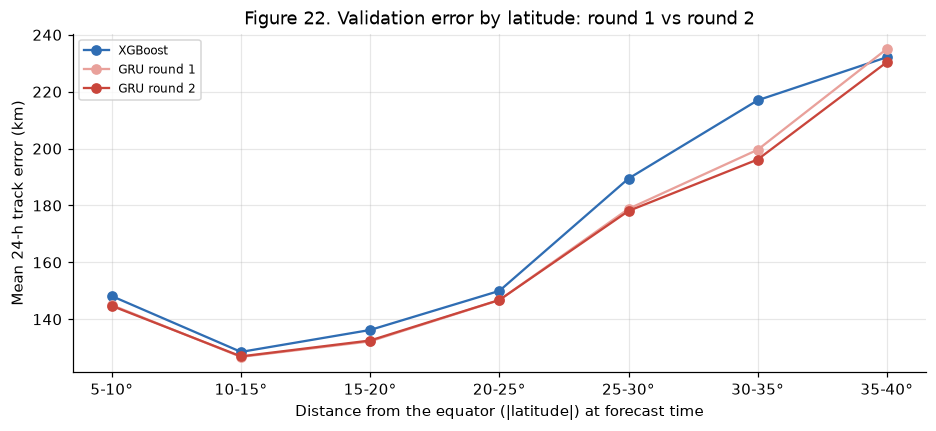

,XGBoost,GRU round 1,GRU round 2
LAT,,,
5,148.1,145.0,144.7
10,128.5,126.8,127.0
15,136.2,132.2,132.5
20,150.0,146.7,146.8
25,189.5,178.8,178.1
30,217.0,199.6,196.2
35,232.1,235.0,230.4


In [12]:
show = ["XGBoost", "GRU round 1", r2_name]
cols = {"XGBoost": "#2F6DB3", "GRU round 1": "#E9A19B", r2_name: "#C9453B"}
bands = (va["LAT"].abs() // 5 * 5).astype(int)
bb = pd.DataFrame({m: err[m] for m in show}).groupby(bands).agg(["mean", "size"])
bb = bb[bb[(show[0], "size")] >= 50]
fig, ax = plt.subplots(figsize=(10, 4))
for m in show:
    ax.plot([f"{b}-{b+5}°" for b in bb.index], bb[(m, "mean")], "o-", color=cols[m], label=m)
ax.set(xlabel="Distance from the equator (|latitude|) at forecast time", ylabel="Mean 24-h track error (km)",
       title="Figure 22. Validation error by latitude: round 1 vs round 2")
ax.legend(fontsize=8)
savefig(fig, "fig22_round2_by_latitude.png")
plt.show()
bb.xs("mean", axis=1, level=1).round(1)

## 7. Choosing the final model and saving

Finally, the decision. The rule, fixed before looking at the results, is simple: round 2 replaces round 1
as the model taken to the test seasons if its validation error is **lower**. And since round 1's score is
the flattering one, a tie also goes to round 2. Either way, the choice and everything needed to rebuild
both candidates are saved for the final evaluation notebook.

In [13]:
r1, r2 = summary.loc["GRU round 1", "mean_km"], summary.loc[r2_name, "mean_km"]
final_choice = "round 2" if r2 <= r1 + 0.3 else "round 1"
print(f"Round 1 GRU: {r1:.1f} km   {r2_name}: {r2:.1f} km   ->   model for the test seasons: {final_choice}")

out = va[["SID", "SEG_ID", "BASIN", "SEASON", "ISO_TIME"]].copy()
out["err_round2_km"] = err[r2_name]
out.to_csv(PROCESSED / "preds_val_round2.csv", index=False)
cfg = {**BEST, "seeds": FINAL_SEEDS, "static_features": STATIC, "step_features": STEP_FEATURES, **fin_stats,
       "search": {"method": "Optuna TPE + median pruning", "trials": len(study.trials),
                  "fit_seasons": "1980-2013", "tune_seasons": "2014-2016", "best_tune_km": study.best_value},
       "final_choice": final_choice}
(MODEL_DIR / "round2_config.json").write_text(json.dumps(cfg, indent=2))
print("saved data/processed/preds_val_round2.csv, data/processed/optuna_trials.csv, models/round2_config.json,",
      ", ".join(sorted(p.name for p in MODEL_DIR.glob("round2_*.pt"))))

Round 1 GRU: 144.0 km   GRU round 2: 143.8 km   ->   model for the test seasons: round 2


saved data/processed/preds_val_round2.csv, data/processed/optuna_trials.csv, models/round2_config.json, round2_gru_seed2024.pt, round2_gru_seed42.pt, round2_gru_seed7.pt


## Summary

So, what did a second, more thorough round of tuning add? To answer plainly: a slightly better model, a much better-justified one, and a clear lesson about where the limit lies.

| | Round 1 (notebook 05) | Round 2 (this notebook) |
|---|---|---|
| Method | One setting at a time, 9 runs | Bayesian optimization (Optuna TPE) with pruning, 40 trials |
| Settings searched | loss, history, width, depth | all of those plus cell, learning rate, dropout, weight decay, batch size, jointly |
| Chosen on | validation seasons (flattering) | held-out 2014–2016 (validation untouched) |
| Configuration | GRU, 48 h, 128×1, dropout 0.1 | GRU, 48 h, 256×2, dropout 0.3, lr 0.0009, batch 1024 |
| Validation mean error | 144.0 km | **143.8 km** |
| North Atlantic / beyond 25° | 155.8 / 191.1 km | **154.3 / 189.2 km** |

What it all means:

- **A real but small gain.** Round 2 is better on every summary measure, but by 0.2–1.9 km, and the bootstrap can't separate the two rounds statistically. By the rule fixed in advance, round 2 is the model taken to the test seasons, and with good reason: its validation score is the honest one.
- **A search that converged on a plateau.** Eight very different configurations scored within 0.2 km of each other on the tuning seasons, and the best result stopped improving after about trial 21. More trials would be very unlikely to help.
- **A limit set by the information, not the tuning.** The GRU's settings are now close to as good as they will get. What's left is the problem noted since notebook 03: these models see only the storm's own past, not the surrounding weather that steers it. Getting much closer to the NHC's 63 km would need new inputs (for example, steering winds from weather-model analyses), not more tuning.
- **Optuna earned its place.** It searched eight settings jointly in under 13 minutes, its pruner saved roughly a third of the compute, and fANOVA showed which settings actually matter (cell type and learning rate) and which don't (depth, weight decay).

Next comes the final evaluation. The round 2 GRU, the round 1 models and every baseline get scored once on the test seasons (2020–2024), which no model, setting or decision has touched so far.

## References

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter
optimization framework. In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge
Discovery & Data Mining* (pp. 2623–2631). https://doi.org/10.1145/3292500.3330701

Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization. In
*Advances in Neural Information Processing Systems 24* (pp. 2546–2554).

Hutter, F., Hoos, H., & Leyton-Brown, K. (2014). An efficient approach for assessing hyperparameter
importance. In *Proceedings of the 31st International Conference on Machine Learning* (pp. 754–762).

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author
reviewed each step, ran the notebook, and checked the outputs.*